# Garment Production Intelligence

## 04 — Statistical Productivity Analysis

### Business Problem
Management wants to understand whether
productivity differences between the sewing
and finishing departments are statistically meaningful.

### Statistical Methods
1. Descriptive statistics
2. Hypothesis testing
3. Confidence intervals
4. Regression analysis

### First Research Question
Is average actual productivity different
between the sewing and finishing departments?

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Identify project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Locate cleaned dataset
file_path = (
    project_dir
    / "data"
    / "processed"
    / "garments_productivity_cleaned.csv"
)

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Total rows: 1197
Total columns: 15


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [2]:

# Separate productivity by department

sewing = df.loc[
    df["department"] == "sewing",
    "actual_productivity"
]

finishing = df.loc[
    df["department"] == "finishing",
    "actual_productivity"
]

print("SEWING")
print("Observations:", len(sewing))
print(f"Average productivity: {sewing.mean():.2%}")
print(f"Standard deviation: {sewing.std():.4f}")

print("\nFINISHING")
print("Observations:", len(finishing))
print(f"Average productivity: {finishing.mean():.2%}")
print(f"Standard deviation: {finishing.std():.4f}")


SEWING
Observations: 691
Average productivity: 72.20%
Standard deviation: 0.1548

FINISHING
Observations: 506
Average productivity: 75.30%
Standard deviation: 0.1970


In [3]:

# Separate productivity observations by department

sewing = df.loc[
    df["department"] == "sewing",
    "actual_productivity"
].dropna()

finishing = df.loc[
    df["department"] == "finishing",
    "actual_productivity"
].dropna()

# Display descriptive statistics
print("SEWING DEPARTMENT")
print("Observations:", len(sewing))
print(f"Mean Productivity: {sewing.mean():.2%}")
print(f"Standard Deviation: {sewing.std():.4f}")

print("\nFINISHING DEPARTMENT")
print("Observations:", len(finishing))
print(f"Mean Productivity: {finishing.mean():.2%}")
print(f"Standard Deviation: {finishing.std():.4f}")


SEWING DEPARTMENT
Observations: 691
Mean Productivity: 72.20%
Standard Deviation: 0.1548

FINISHING DEPARTMENT
Observations: 506
Mean Productivity: 75.30%
Standard Deviation: 0.1970


## Welch's Two-Sample t-Test

### Research Question
Is average actual productivity different between
the sewing and finishing departments?

### Null Hypothesis (H0)
The population mean productivity of sewing
and finishing is equal.

H0: μ_sewing = μ_finishing

### Alternative Hypothesis (H1)
The population mean productivity is different.

H1: μ_sewing ≠ μ_finishing

### Significance Level
α = 0.05

### Statistical Method
Welch's two-sample t-test.

In [4]:

# Welch's two-sample t-test

t_statistic, p_value = stats.ttest_ind(
    sewing,
    finishing,
    equal_var=False,
    alternative="two-sided"
)

alpha = 0.05

print("WELCH'S TWO-SAMPLE T-TEST")
print("-" * 40)

print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance level: {alpha}")

if p_value < alpha:
    print("Result: Reject H0")
    print("The department means differ statistically.")
else:
    print("Result: Fail to reject H0")
    print("Insufficient evidence of a difference.")


WELCH'S TWO-SAMPLE T-TEST
----------------------------------------
T-statistic: -2.9314
P-value: 0.003458
Significance level: 0.05
Result: Reject H0
The department means differ statistically.


## 95% Confidence Interval for Mean Productivity Difference

### Objective
Estimate the difference in average actual productivity
between sewing and finishing departments.

### Statistical Method
Welch's confidence interval for two independent means.

### Confidence Level
95%

### Difference Definition
Mean Sewing Productivity - Mean Finishing Productivity

### Limitation
This interval assumes independent observations.
Repeated observations from the same teams may
violate that assumption.

In [5]:

# Calculate Welch's 95% confidence interval

test_result = stats.ttest_ind(
    sewing,
    finishing,
    equal_var=False,
    alternative="two-sided"
)

# Obtain 95% confidence interval
ci = test_result.confidence_interval(
    confidence_level=0.95
)

# Difference in average productivity
mean_difference = sewing.mean() - finishing.mean()

print("95% CONFIDENCE INTERVAL")
print("-" * 45)

print(
    f"Mean Difference: "
    f"{mean_difference * 100:.2f} percentage points"
)

print(
    f"Lower Bound: "
    f"{ci.low * 100:.2f} percentage points"
)

print(
    f"Upper Bound: "
    f"{ci.high * 100:.2f} percentage points"
)

print(f"P-value: {test_result.pvalue:.6f}")


95% CONFIDENCE INTERVAL
---------------------------------------------
Mean Difference: -3.09 percentage points
Lower Bound: -5.17 percentage points
Upper Bound: -1.02 percentage points
P-value: 0.003458


## Visualization of the Mean Productivity Difference

### Objective
Visualize the estimated productivity difference between
the sewing and finishing departments with a 95%
confidence interval.

The difference is calculated as:
Sewing Mean - Finishing Mean.

This is an exploratory confidence interval because
the observations may not be independent.

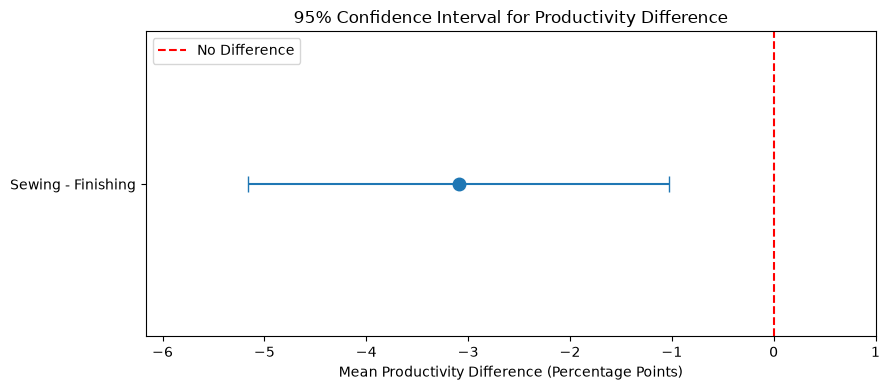

In [6]:

# Visualize Welch's 95% confidence interval

import matplotlib.pyplot as plt

# Convert values to percentage points
difference_pp = mean_difference * 100
lower_pp = ci.low * 100
upper_pp = ci.high * 100

# Calculate distances from estimate to CI bounds
lower_error = difference_pp - lower_pp
upper_error = upper_pp - difference_pp

fig, ax = plt.subplots(figsize=(9, 4))

ax.errorbar(
    x=[difference_pp],
    y=[0],
    xerr=[[lower_error], [upper_error]],
    fmt="o",
    capsize=6,
    markersize=9
)

# Reference line for no difference
ax.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="No Difference"
)

ax.set_yticks([0])
ax.set_yticklabels(["Sewing - Finishing"])

ax.set_xlabel("Mean Productivity Difference (Percentage Points)")
ax.set_title("95% Confidence Interval for Productivity Difference")

ax.set_xlim(
    min(lower_pp - 1, -1),
    max(upper_pp + 1, 1)
)

ax.legend()
plt.tight_layout()
plt.show()


### Statistical Interpretation

The estimated mean productivity difference between
sewing and finishing is -3.09 percentage points.

The 95% Welch confidence interval ranges from
-5.17 to -1.02 percentage points.

The interval excludes zero, consistent with the
exploratory Welch t-test result (p = 0.003458).

Finishing recorded higher average productivity
than sewing in the observed dataset.

However, the confidence interval assumes independent
observations. Repeated observations from production
teams may violate this assumption.

Further analysis accounting for team-level dependence
is needed before drawing stronger statistical conclusions.

## Repeated Production Team Observations

### Objective
Investigate repeated observations from the same
production teams across different dates.

### Why This Matters
Traditional two-sample t-tests assume observations
are independent.

Repeated observations from the same production team
may violate this assumption.

### Next Statistical Method
We will investigate regression with
cluster-robust standard errors.

In [7]:

# Identify unique department-team groups

df["team_group"] = (
    df["department"].astype(str)
    + "_team_"
    + df["team"].astype(str)
)

print("REPEATED TEAM OBSERVATION ANALYSIS")
print("-" * 45)

print("Total observations:", len(df))

print(
    "Unique department-team groups:",
    df["team_group"].nunique()
)

print("\nUnique groups by department:")

print(
    df.groupby("department")["team_group"].nunique()
)


REPEATED TEAM OBSERVATION ANALYSIS
---------------------------------------------
Total observations: 1197
Unique department-team groups: 24

Unique groups by department:
department
finishing    12
sewing       12
Name: team_group, dtype: int64


In [8]:

# Count repeated observations by team

team_observation_counts = (
    df.groupby(["department", "team"])
    .agg(
        total_observations=("actual_productivity", "size"),
        unique_dates=("date", "nunique")
    )
    .reset_index()
)

print("OBSERVATIONS PER TEAM")
print("-" * 45)

display(team_observation_counts)

print("\nSummary:")
print(
    team_observation_counts[
        ["total_observations", "unique_dates"]
    ].describe().round(2)
)


OBSERVATIONS PER TEAM
---------------------------------------------


,department,team,total_observations,unique_dates
0,finishing,1,49,49
1,finishing,2,52,52
2,finishing,3,37,37
3,finishing,4,46,46
4,finishing,5,35,35
5,finishing,6,35,35
6,finishing,7,41,41
7,finishing,8,53,53
8,finishing,9,46,46
9,finishing,10,43,43



Summary:
       total_observations  unique_dates
count               24.00         24.00
mean                49.88         49.88
std                  9.43          9.43
min                 29.00         29.00
25%                 42.50         42.50
50%                 54.00         54.00
75%                 58.00         58.00
max                 59.00         59.00


In [9]:

# Check repeated production team groups

repeated_groups = (
    team_observation_counts["total_observations"] > 1
).sum()

single_observation_groups = (
    team_observation_counts["total_observations"] == 1
).sum()

print("REPEATED OBSERVATION SUMMARY")
print("-" * 45)

print("Groups with repeated observations:", repeated_groups)

print(
    "Groups with one observation:",
    single_observation_groups
)

print(
    "Total department-team groups:",
    len(team_observation_counts)
)


REPEATED OBSERVATION SUMMARY
---------------------------------------------
Groups with repeated observations: 24
Groups with one observation: 0
Total department-team groups: 24


## Cluster-Robust Regression Analysis

### Business Question
Does average productivity differ between sewing
and finishing after accounting for repeated
observations within production teams?

### Statistical Method
Ordinary Least Squares (OLS) regression with
cluster-robust standard errors.

### Clustering Variable
Department-Team combination (24 groups).

### Model
Actual Productivity = β0 + β1(Sewing) + Error

### Interpretation
β0 represents the average finishing productivity.

β1 represents the average productivity difference
between sewing and finishing.

Cluster-robust standard errors allow observations
within the same team group to be correlated.

In [10]:

# Cluster-robust regression

import statsmodels.formula.api as smf

# Create a working copy
regression_df = df.copy()

# Create sewing indicator
# Sewing = 1, Finishing = 0
regression_df["is_sewing"] = (
    regression_df["department"] == "sewing"
).astype(int)

# Create unique department-team identifiers
regression_df["team_group"] = (
    regression_df["department"].astype(str)
    + "_team_"
    + regression_df["team"].astype(str)
)

# Fit OLS model with cluster-robust standard errors
cluster_model = smf.ols(
    formula="actual_productivity ~ is_sewing",
    data=regression_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": regression_df["team_group"],
        "use_correction": True
    },
    use_t=True
)

print(cluster_model.summary())


                             OLS Regression Results                            
Dep. Variable:     actual_productivity   R-squared:                       0.008
Model:                             OLS   Adj. R-squared:                  0.007
Method:                  Least Squares   F-statistic:                     1.641
Date:                 Tue, 17 Nov 2026   Prob (F-statistic):              0.213
Time:                         15:48:36   Log-Likelihood:                 396.49
No. Observations:                 1197   AIC:                            -789.0
Df Residuals:                     1195   BIC:                            -778.8
Df Model:                            1                                         
Covariance Type:               cluster                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.7530      0.019     40.47

## Comparing Statistical Methods

### Objective
Compare Welch's t-test with cluster-robust regression
to investigate how accounting for repeated team
observations changes statistical uncertainty.

### Methods
1. Welch's two-sample t-test
2. OLS regression with cluster-robust standard errors

### Important
The dataset contains 24 department-team groups.
All groups contain repeated observations.

In [11]:

# Extract cluster-robust regression results

coefficient = cluster_model.params["is_sewing"]
standard_error = cluster_model.bse["is_sewing"]
p_value_cluster = cluster_model.pvalues["is_sewing"]

# 95% confidence interval
cluster_ci = cluster_model.conf_int().loc["is_sewing"]

print("CLUSTER-ROBUST REGRESSION RESULTS")
print("-" * 45)

print(f"Mean difference: {coefficient * 100:.2f} pp")
print(f"Standard error: {standard_error:.4f}")
print(f"P-value: {p_value_cluster:.4f}")

print(
    f"95% CI: [{cluster_ci.iloc[0] * 100:.2f}, "
    f"{cluster_ci.iloc[1] * 100:.2f}] percentage points"
)


CLUSTER-ROBUST REGRESSION RESULTS
---------------------------------------------
Mean difference: -3.09 pp
Standard error: 0.0241
P-value: 0.2129
95% CI: [-8.09, 1.90] percentage points


In [12]:

# Compare Welch and cluster-robust results

comparison_table = pd.DataFrame({
    "Method": [
        "Welch's t-test",
        "Cluster-robust OLS"
    ],
    "Difference (pp)": [
        mean_difference * 100,
        coefficient * 100
    ],
    "P-value": [
        test_result.pvalue,
        p_value_cluster
    ],
    "CI Lower (pp)": [
        ci.low * 100,
        cluster_ci.iloc[0] * 100
    ],
    "CI Upper (pp)": [
        ci.high * 100,
        cluster_ci.iloc[1] * 100
    ]
})

display(comparison_table.round(4))


,Method,Difference (pp),P-value,CI Lower (pp),CI Upper (pp)
0,Welch's t-test,-3.0938,0.0035,-5.1650,-1.0225
1,Cluster-robust OLS,-3.0938,0.2129,-8.0892,1.9017



### Statistical Findings and Business Interpretation

The estimated average productivity difference between
sewing and finishing is approximately -3.09 percentage
points.

Welch's t-test produced p = 0.003458, suggesting a
statistically significant difference under the
independent-observations assumption.

However, cluster-robust regression produced p = 0.213,
which is not significant at the 5% level.

Accounting for repeated observations within teams
increases the uncertainty of the estimated difference.

### Business Implications

Management should not conclude that sewing is
systematically less productive based only on
the ordinary two-sample t-test.

Production performance should also be investigated
using operational factors such as SMV, overtime,
workforce size and garment style changes.

### Statistical Limitations

Cluster-robust inference is an improvement for
within-team dependence, but only 24 clusters are
available.

The model does not establish a causal department effect.

Additional sensitivity checks and models accounting
for other operational factors are recommended.



## Final Statistical Findings — Department Productivity

### Research Question

Is average actual productivity different between
the sewing and finishing departments?

### Observed Mean Difference

Sewing - Finishing = -3.0938 percentage points.

### Welch's Two-Sample t-Test

- P-value: 0.0035
- 95% CI: [-5.1650, -1.0225] percentage points
- Decision: Reject H0 at the 5% level

### Cluster-Robust Regression

- Clustering variable: Department-Team
- Number of clusters: 24
- P-value: 0.2129
- 95% CI: [-8.0892, 1.9017] percentage points
- Decision: Fail to reject H0 at the 5% level

### Key Findings

1. Sewing recorded lower average productivity
   than finishing in the observed dataset.

2. Welch's t-test suggests a statistically
   significant difference under independence.

3. Cluster-robust regression produces a wider
   confidence interval that includes zero.

4. The statistical evidence for a department
   difference becomes weaker after accounting
   for repeated observations within teams.

### Business Recommendations

- Avoid ranking departments using average
  productivity alone.
- Monitor production performance by team.
- Investigate SMV, overtime, workforce size,
  incentives and garment style changes.
- Consider operational differences when
  comparing department performance.

### Limitations

The dataset contains repeated team observations.

Only 24 department-team clusters are available,
so cluster-robust inference remains approximate.

The analysis is observational and does not
establish a causal department effect.


## Multiple Linear Regression — Operational Productivity

### Business Question
Which operational factors are associated with actual
garment productivity after adjusting for other factors?

### Response Variable
actual_productivity

### Explanatory Variables
- department
- smv
- over_time
- no_of_workers
- no_of_style_change
- incentive
- idle_time

### Statistical Method
Multiple Linear Regression (OLS)

### Inference
Cluster-robust standard errors using
department-team groups.

### Limitations
This is an observational study.
Regression associations do not establish causation.

In [13]:

# Prepare data for multiple linear regression

model_columns = [
    "actual_productivity",
    "department",
    "team",
    "smv",
    "over_time",
    "no_of_workers",
    "no_of_style_change",
    "incentive",
    "idle_time"
]

# Create a separate working dataset
multiple_df = df[model_columns].copy()

# Create department-team group identifier
multiple_df["team_group"] = (
    multiple_df["department"].astype(str)
    + "_team_"
    + multiple_df["team"].astype(str)
)

# Check missing values
print("MISSING VALUES")
print(multiple_df.isna().sum())

# Remove incomplete rows for selected model variables
multiple_df = multiple_df.dropna().copy()

print("\nMULTIPLE REGRESSION DATA")
print("Total observations:", len(multiple_df))
print("Total team groups:", multiple_df["team_group"].nunique())

display(multiple_df.head())


MISSING VALUES
actual_productivity    0
department             0
team                   0
smv                    0
over_time              0
no_of_workers          0
no_of_style_change     0
incentive              0
idle_time              0
team_group             0
dtype: int64

MULTIPLE REGRESSION DATA
Total observations: 1197
Total team groups: 24


,actual_productivity,department,team,smv,over_time,no_of_workers,no_of_style_change,incentive,idle_time,team_group
0,0.940725,sewing,8,26.16,7080,59.0,0,98,0.0,sewing_team_8
1,0.886500,finishing,1,3.94,960,8.0,0,0,0.0,finishing_team_1
2,0.800570,sewing,11,11.41,3660,30.5,0,50,0.0,sewing_team_11
3,0.800570,sewing,12,11.41,3660,30.5,0,50,0.0,sewing_team_12
4,0.800382,sewing,6,25.90,1920,56.0,0,50,0.0,sewing_team_6


In [14]:

# Multiple linear regression with cluster-robust errors

import statsmodels.formula.api as smf

formula = (
    "actual_productivity ~ "
    "C(department) + "
    "smv + "
    "over_time + "
    "no_of_workers + "
    "no_of_style_change + "
    "incentive + "
    "idle_time"
)

multiple_model = smf.ols(
    formula=formula,
    data=multiple_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": multiple_df["team_group"],
        "use_correction": True,
        "df_correction": True
    },
    use_t=True
)

print(multiple_model.summary())


                             OLS Regression Results                            
Dep. Variable:     actual_productivity   R-squared:                       0.092
Model:                             OLS   Adj. R-squared:                  0.087
Method:                  Least Squares   F-statistic:                     6.204
Date:                 Tue, 17 Nov 2026   Prob (F-statistic):           0.000372
Time:                         15:48:37   Log-Likelihood:                 449.86
No. Observations:                 1197   AIC:                            -883.7
Df Residuals:                     1189   BIC:                            -843.0
Df Model:                            7                                         
Covariance Type:               cluster                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept       

## Multiple Regression — Model Interpretation

### Objective
Examine the estimated relationships between
operational factors and actual productivity
after adjusting for other included variables.

### Statistical Method
Multiple Linear Regression with cluster-robust
standard errors.

### Important Considerations
- Coefficients represent adjusted associations.
- Statistical significance does not prove causation.
- Multicollinearity and influential observations
  must be investigated before final conclusions.

In [15]:

# Create a readable multiple regression results table

regression_results = pd.DataFrame({
    "Variable": multiple_model.params.index,
    "Coefficient": multiple_model.params.values,
    "Std Error": multiple_model.bse.values,
    "P-value": multiple_model.pvalues.values,
    "CI Lower": multiple_model.conf_int().iloc[:, 0].values,
    "CI Upper": multiple_model.conf_int().iloc[:, 1].values
})

# Convert coefficients and CI bounds to
# productivity percentage points
for column in [
    "Coefficient", "Std Error", "CI Lower", "CI Upper"
]:
    regression_results[column] *= 100

print("MULTIPLE REGRESSION RESULTS")
print("-" * 50)

display(regression_results.round(4))

print(f"\nR-squared: {multiple_model.rsquared:.4f}")
print(f"Adjusted R-squared: {multiple_model.rsquared_adj:.4f}")
print(f"Observations: {int(multiple_model.nobs)}")


MULTIPLE REGRESSION RESULTS
--------------------------------------------------


,Variable,Coefficient,Std Error,P-value,CI Lower,CI Upper
0,Intercept,73.0479,2.5586,0.0000,67.7550,78.3408
1,C(department)[T.sewing],-9.1452,6.7002,0.1855,-23.0056,4.7152
2,smv,-0.5627,0.1676,0.0027,-0.9095,-0.2159
3,over_time,-0.0006,0.0003,0.0681,-0.0012,0.0000
4,no_of_workers,0.5260,0.1945,0.0126,0.1237,0.9284
5,no_of_style_change,-9.3806,2.3557,0.0006,-14.2538,-4.5075
6,incentive,0.0065,0.0039,0.1090,-0.0016,0.0145
7,idle_time,-0.1171,0.0375,0.0048,-0.1947,-0.0394



R-squared: 0.0923
Adjusted R-squared: 0.0870
Observations: 1197


## Multicollinearity Analysis — Variance Inflation Factor

### Objective
Check whether the explanatory variables in the
multiple regression model are highly correlated.

### Method
Variance Inflation Factor (VIF).

### Important
High multicollinearity can increase coefficient
standard errors and make individual coefficient
estimates less stable.

VIF measures relationships among explanatory
variables, not their relationship with productivity.

In [16]:

# Calculate Variance Inflation Factors (VIF)

import pandas as pd
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Use the explanatory variables from the fitted model
X = multiple_model.model.exog

variable_names = multiple_model.model.exog_names

# Calculate VIF, excluding the intercept
vif_results = pd.DataFrame({
    "Variable": [
        variable_names[i]
        for i in range(len(variable_names))
        if variable_names[i] != "Intercept"
    ],
    "VIF": [
        variance_inflation_factor(X, i)
        for i in range(len(variable_names))
        if variable_names[i] != "Intercept"
    ]
})

# Sort from highest to lowest VIF
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

print("MULTICOLLINEARITY ANALYSIS")
print("-" * 45)

display(vif_results.round(2))


MULTICOLLINEARITY ANALYSIS
---------------------------------------------


,Variable,VIF
3,no_of_workers,14.04
0,C(department)[T.sewing],8.68
1,smv,6.07
2,over_time,2.38
4,no_of_style_change,1.23
5,incentive,1.01
6,idle_time,1.01


## Investigation of Multicollinearity

### Objective
Identify correlations among the explanatory
variables used in the multiple regression model.

### Variables of Special Interest
- Department
- Number of workers
- Standard Minute Value (SMV)
- Overtime

### Method
Pearson correlation matrix and heatmap.

### Important Note
Correlation between explanatory variables
may make regression coefficients unstable.

In [17]:

# Prepare explanatory variables

correlation_df = multiple_df[
    [
        "smv",
        "over_time",
        "no_of_workers",
        "no_of_style_change",
        "incentive",
        "idle_time"
    ]
].copy()

# Convert department to a numerical indicator
correlation_df["is_sewing"] = (
    multiple_df["department"] == "sewing"
).astype(int)

# Calculate Pearson correlation matrix
correlation_matrix = correlation_df.corr()

print("EXPLANATORY VARIABLE CORRELATIONS")

display(correlation_matrix.round(2))


EXPLANATORY VARIABLE CORRELATIONS


,smv,over_time,no_of_workers,no_of_style_change,incentive,idle_time,is_sewing
smv,1.00,0.67,0.91,0.32,0.03,0.06,0.87
over_time,0.67,1.00,0.73,0.06,-0.00,0.03,0.68
no_of_workers,0.91,0.73,1.00,0.33,0.05,0.06,0.94
no_of_style_change,0.32,0.06,0.33,1.00,-0.03,-0.01,0.30
incentive,0.03,-0.00,0.05,-0.03,1.00,-0.01,0.05
idle_time,0.06,0.03,0.06,-0.01,-0.01,1.00,0.05
is_sewing,0.87,0.68,0.94,0.30,0.05,0.05,1.00


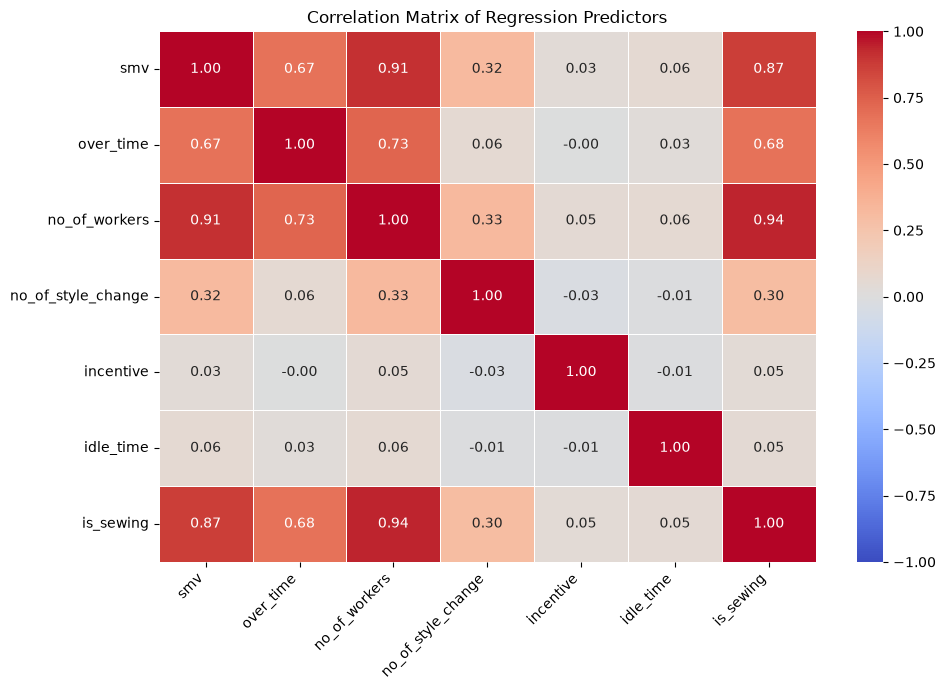

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Matrix of Regression Predictors")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


## Department-Specific Multicollinearity Investigation

### Objective

Investigate relationships among SMV, workforce size,
and overtime separately for sewing and finishing.

### Business Reason

Sewing and finishing have different production
processes, workforce sizes, and standard task times.

Strong overall correlations may partly reflect
these department differences.

### Method

Department-specific Pearson correlation matrices.

### Limitation

Lower correlations within departments do not
automatically eliminate multicollinearity.

In [19]:

# Department-specific correlation analysis

variables = [
    "smv",
    "no_of_workers",
    "over_time"
]

for department, group in multiple_df.groupby("department"):

    print(f"\n{department.upper()} DEPARTMENT")
    print("-" * 40)

    department_corr = group[variables].corr()

    display(department_corr.round(3))



FINISHING DEPARTMENT
----------------------------------------


,smv,no_of_workers,over_time
smv,1.000,0.205,0.150
no_of_workers,0.205,1.000,0.627
over_time,0.150,0.627,1.000



SEWING DEPARTMENT
----------------------------------------


,smv,no_of_workers,over_time
smv,1.000,0.578,0.257
no_of_workers,0.578,1.000,0.346
over_time,0.257,0.346,1.000


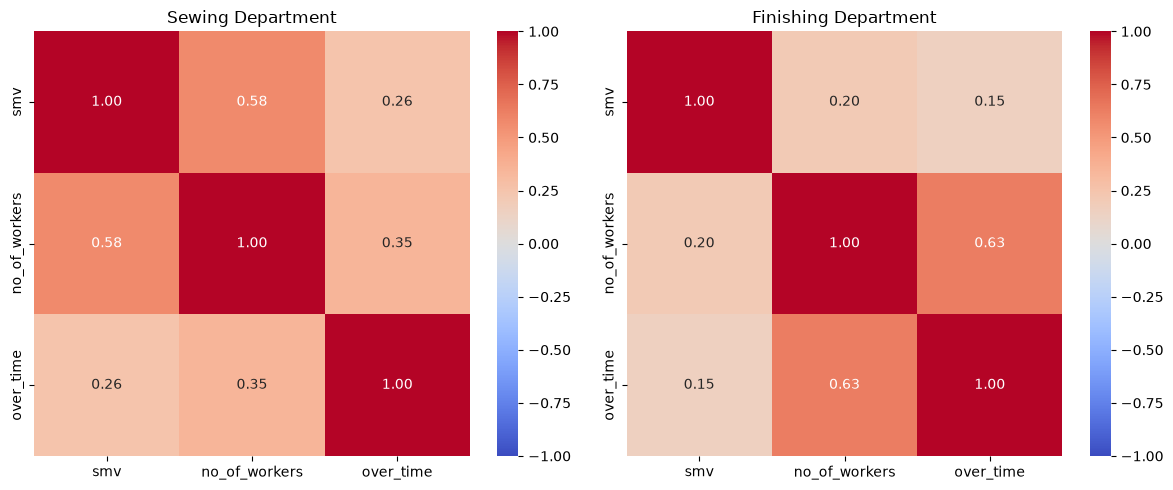

In [20]:

# Compare predictor correlations within departments

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

departments = ["sewing", "finishing"]

for ax, department in zip(axes, departments):

    subset = multiple_df[
        multiple_df["department"] == department
    ]

    corr = subset[variables].corr()

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        ax=ax
    )

    ax.set_title(f"{department.title()} Department")

plt.tight_layout()
plt.show()


## Multiple Regression — Residual Diagnostics

### Objective
Evaluate the multiple regression model using
residuals and fitted productivity values.

### Key Questions
- Are residuals randomly scattered around zero?
- Do residuals show curved or systematic patterns?
- Does the variability of residuals change
  across predicted productivity values?

### Method
Residuals vs Fitted Values scatter plot.

### Important Note
Cluster-robust standard errors adjust statistical
uncertainty but do not automatically fix problems
with the regression model's functional form.

In [21]:

# Calculate fitted values and residuals

diagnostics_df = pd.DataFrame({
    "fitted_productivity": multiple_model.fittedvalues,
    "residual": multiple_model.resid
})

# Convert ratios to percentage points
diagnostics_df["fitted_productivity"] *= 100
diagnostics_df["residual"] *= 100

print("REGRESSION DIAGNOSTICS")
print("-" * 45)

print("Residual summary:")
display(diagnostics_df["residual"].describe().round(2))

print("\nFirst five observations:")
display(diagnostics_df.head().round(2))


REGRESSION DIAGNOSTICS
---------------------------------------------
Residual summary:


count    1197.00
mean        0.00
std        16.62
min       -54.85
25%        -8.03
50%         4.37
75%        11.09
max        37.58
Name: residual, dtype: float64


First five observations:


,fitted_productivity,residual
0,76.60,17.47
1,74.46,14.19
2,71.65,8.40
3,71.65,8.40
4,77.96,2.08


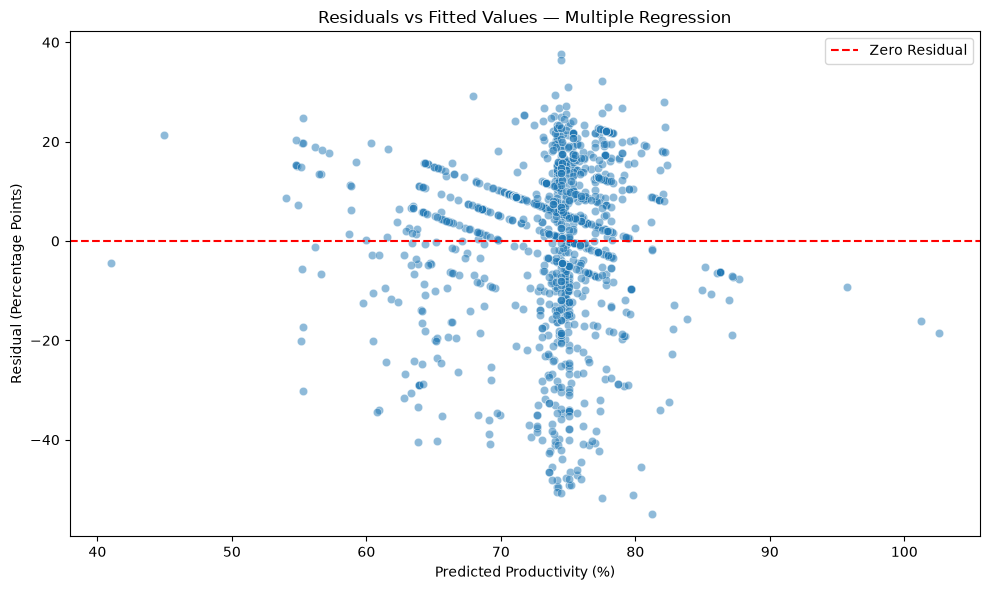

In [22]:

# Residuals vs fitted values

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=diagnostics_df,
    x="fitted_productivity",
    y="residual",
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.title("Residuals vs Fitted Values — Multiple Regression")
plt.xlabel("Predicted Productivity (%)")
plt.ylabel("Residual (Percentage Points)")

plt.legend()
plt.tight_layout()
plt.show()


## Influential Observation Analysis — Cook's Distance

### Objective
Identify production observations that may strongly
influence the multiple regression model.

### Method
Cook's Distance.

### Important Considerations
- High Cook's Distance does not automatically
  indicate an incorrect observation.
- Influential observations should be investigated
  before considering any changes to the dataset.
- The original dataset will remain unchanged.

In [23]:

# Calculate Cook's Distance

from statsmodels.stats.outliers_influence import OLSInfluence

# Calculate influence diagnostics
influence = OLSInfluence(multiple_model)

# Extract Cook's Distance
cooks_distance = influence.cooks_distance[0]

# Screening threshold
n = len(cooks_distance)
threshold = 4 / n

print("COOK'S DISTANCE ANALYSIS")
print("-" * 45)

print("Total observations:", n)
print(f"Screening threshold (4/n): {threshold:.6f}")

# Count observations above threshold
influential_count = (cooks_distance > threshold).sum()

print(
    "Observations above threshold:",
    influential_count
)


COOK'S DISTANCE ANALYSIS
---------------------------------------------
Total observations: 1197
Screening threshold (4/n): 0.003342
Observations above threshold: 35


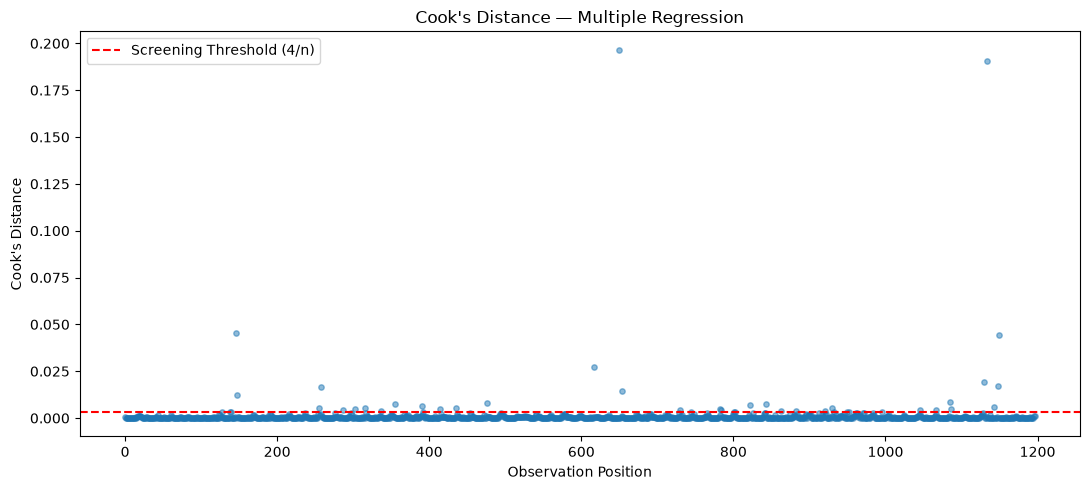

In [24]:

# Visualize Cook's Distance

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    np.arange(len(cooks_distance)),
    cooks_distance,
    alpha=0.5,
    s=15
)

ax.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Screening Threshold (4/n)"
)

ax.set_title("Cook's Distance — Multiple Regression")
ax.set_xlabel("Observation Position")
ax.set_ylabel("Cook's Distance")

ax.legend()
plt.tight_layout()
plt.show()


In [25]:

# Identify observations with the highest Cook's Distance

influence_results = multiple_df.copy()

influence_results["cooks_distance"] = np.asarray(
    cooks_distance
)

top_influential = influence_results.nlargest(
    10,
    "cooks_distance"
)

print("TOP 10 INFLUENTIAL OBSERVATIONS")

display(
    top_influential[
        [
            "department",
            "team",
            "actual_productivity",
            "smv",
            "no_of_workers",
            "incentive",
            "cooks_distance"
        ]
    ].round(4)
)


TOP 10 INFLUENTIAL OBSERVATIONS


,department,team,actual_productivity,smv,no_of_workers,incentive,cooks_distance
650,sewing,7,0.6623,24.26,58.0,0,0.1966
1133,finishing,9,0.8410,2.90,15.0,3600,0.1904
146,sewing,11,0.3500,12.52,54.0,38,0.0453
1149,finishing,8,0.2641,3.90,8.0,960,0.0441
617,sewing,4,0.3507,30.10,55.5,23,0.0273
1130,finishing,5,0.8643,3.94,12.0,2880,0.0195
1148,finishing,10,0.4773,2.90,8.0,960,0.0170
257,sewing,2,0.3112,51.02,57.0,27,0.0163
654,sewing,8,0.3653,24.26,57.0,0,0.0146
147,sewing,5,0.2337,42.41,57.0,0,0.0124


## Cook's Distance — Final Investigation

### Objective
Examine the number and magnitude of potentially
influential production observations.

### Important Note
Cook's Distance measures influence on the fitted
regression model.

The 4/n threshold is a screening guideline,
not a rule for deleting observations.

In [26]:

# Summarize potentially influential observations

import numpy as np

cooks_values = np.asarray(cooks_distance)

flagged_count = int(
    np.sum(cooks_values > threshold)
)

flagged_percentage = (
    flagged_count / len(cooks_values) * 100
)

print("COOK'S DISTANCE - FINAL RESULTS")
print("-" * 45)

print(f"Total observations: {len(cooks_values)}")
print(f"Screening threshold: {threshold:.6f}")
print(f"Flagged observations: {flagged_count}")
print(f"Flagged percentage: {flagged_percentage:.2f}%")
print(f"Maximum Cook's Distance: {np.max(cooks_values):.6f}")

print("\nTOP 10 COOK'S DISTANCE VALUES")

top_cooks = (
    influence_results[
        ["department", "team", "cooks_distance"]
    ]
    .sort_values("cooks_distance", ascending=False)
    .head(10)
)

display(top_cooks.round(6))


COOK'S DISTANCE - FINAL RESULTS
---------------------------------------------
Total observations: 1197
Screening threshold: 0.003342
Flagged observations: 35
Flagged percentage: 2.92%
Maximum Cook's Distance: 0.196580

TOP 10 COOK'S DISTANCE VALUES


,department,team,cooks_distance
650,sewing,7,0.196580
1133,finishing,9,0.190399
146,sewing,11,0.045338
1149,finishing,8,0.044132
617,sewing,4,0.027256
1130,finishing,5,0.019482
1148,finishing,10,0.016991
257,sewing,2,0.016348
654,sewing,8,0.014640
147,sewing,5,0.012411


## Regression Sensitivity Analysis

### Business Question
Are the multiple regression findings sensitive
to potentially influential observations?

### Method
Compare the original regression model with a
sensitivity model excluding observations with
Cook's Distance greater than 4/n.

### Important Notes
- The original dataset remains unchanged.
- Influential observations are not necessarily errors.
- Both models use cluster-robust standard errors.
- Results will be interpreted as associations,
  not causal effects.

In [27]:

# Regression sensitivity analysis

import numpy as np
import statsmodels.formula.api as smf

# Identify observations below the Cook's Distance threshold
keep_mask = np.asarray(cooks_distance) <= threshold

# Create a separate sensitivity dataset
sensitivity_df = multiple_df.iloc[
    np.flatnonzero(keep_mask)
].copy()

print("REGRESSION SENSITIVITY ANALYSIS")
print("-" * 45)

print("Original records:", len(multiple_df))
print("Sensitivity records:", len(sensitivity_df))
print(
    "Excluded for sensitivity check:",
    len(multiple_df) - len(sensitivity_df)
)

print(
    "Remaining department-team groups:",
    sensitivity_df["team_group"].nunique()
)

# Fit regression using the same formula
sensitivity_model = smf.ols(
    formula=formula,
    data=sensitivity_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": sensitivity_df["team_group"],
        "use_correction": True,
        "df_correction": True
    },
    use_t=True
)

print("\nSensitivity model fitted successfully!")


REGRESSION SENSITIVITY ANALYSIS
---------------------------------------------
Original records: 1197
Sensitivity records: 1162
Excluded for sensitivity check: 35
Remaining department-team groups: 24

Sensitivity model fitted successfully!


In [28]:

# Compare original and sensitivity regression results

sensitivity_comparison = pd.DataFrame({
    "Original Coef (pp)": multiple_model.params * 100,
    "Sensitivity Coef (pp)": sensitivity_model.params * 100,
    "Original P-value": multiple_model.pvalues,
    "Sensitivity P-value": sensitivity_model.pvalues
})

sensitivity_comparison["Change (pp)"] = (
    sensitivity_comparison["Sensitivity Coef (pp)"]
    - sensitivity_comparison["Original Coef (pp)"]
)

print("REGRESSION MODEL COMPARISON")
print("-" * 45)

display(sensitivity_comparison.round(4))

print("\nMODEL R-SQUARED")

print(
    f"Original model: {multiple_model.rsquared:.4f}"
)

print(
    f"Sensitivity model: {sensitivity_model.rsquared:.4f}"
)


REGRESSION MODEL COMPARISON
---------------------------------------------


,Original Coef (pp),Sensitivity Coef (pp),Original P-value,Sensitivity P-value,Change (pp)
Intercept,73.0479,73.3325,0.0000,0.0000,0.2846
C(department)[T.sewing],-9.1452,-9.0041,0.1855,0.1685,0.1411
smv,-0.5627,-0.5563,0.0027,0.0072,0.0064
over_time,-0.0006,-0.0005,0.0681,0.0872,0.0001
no_of_workers,0.5260,0.4972,0.0126,0.0174,-0.0289
no_of_style_change,-9.3806,-8.5376,0.0006,0.0003,0.8431
incentive,0.0065,0.0331,0.1090,0.0463,0.0267
idle_time,-0.1171,-0.1539,0.0048,0.0875,-0.0368



MODEL R-SQUARED
Original model: 0.0923
Sensitivity model: 0.0989


In [29]:

# Verify original and sensitivity samples

print("FINAL SAMPLE VERIFICATION")
print("-" * 40)

print("Original records:", len(multiple_df))
print("Sensitivity records:", len(sensitivity_df))
print(
    "Excluded records:",
    len(multiple_df) - len(sensitivity_df)
)

print(
    "Original team groups:",
    multiple_df["team_group"].nunique()
)

print(
    "Remaining team groups:",
    sensitivity_df["team_group"].nunique()
)


FINAL SAMPLE VERIFICATION
----------------------------------------
Original records: 1197
Sensitivity records: 1162
Excluded records: 35
Original team groups: 24
Remaining team groups: 24



## Multiple Regression — Final Statistical Findings

### 1. Model Overview

The analysis examined relationships between actual garment
productivity and seven operational explanatory variables.

- Original observations: 1,197
- Department-team clusters: 24
- Original R-squared: 0.0923
- Sensitivity R-squared: 0.0989

Both models used OLS regression with cluster-robust
standard errors.

### 2. Multicollinearity Findings

The original model showed elevated VIF values:

- Number of workers: 14.04
- Department: 8.68
- SMV: 6.07

Department-specific analysis suggested that differences
between sewing and finishing contribute to the strong
relationships among these explanatory variables.

### 3. Influential Observations

Cook's Distance identified 35 observations (2.92%)
above the screening threshold of 0.003342.

The maximum Cook's Distance was 0.196580.

These observations were excluded only in a separate
sensitivity analysis. The original dataset was preserved.

### 4. Sensitivity Analysis Findings

SMV, workforce size and style changes retained similar
coefficient directions and remained statistically
significant at the 5% level in both models.

The incentive coefficient changed from +0.0065 to
+0.0331 percentage points per BDT.

The incentive p-value changed from 0.1090 to 0.0463.

The idle-time p-value changed from 0.0048 to 0.0875.

These results indicate that the incentive and idle-time
findings are sensitive to influential observations.

### 5. Business Recommendations

- Investigate garment style changes and their operational
  requirements.
- Monitor SMV together with workforce allocation.
- Compare manufacturing performance within departments.
- Investigate unusually high incentive payments.
- Avoid recommending staffing or incentive changes based
  solely on regression coefficients.

### 6. Limitations

The original model explained 9.23% of observed
productivity variation.

Multicollinearity may affect the precision and
interpretation of some coefficients.

Only 24 department-team clusters are available.

Cook's Distance screening is exploratory and does not
justify automatic deletion of records.

The data is observational, and these regression
associations do not establish causation.
